# Employee Salary Dataset — Machine Learning Project

**Goal:** Build a machine learning regression model that predicts employee salary based on experience, education, job role, skills, location, and other relevant factors.

This notebook covers a full ML pipeline:

0. Setup - Import Libraries
1. Load the Data
2. Initial Exploration
3. Check for Data Leakage
4. Feature Engineering
5. Encode Categorical Features & Prepare X/y
6. Train/Test Split
7. Baseline: Mean Salary Predictor
8. Train Multiple Models
9. Compare Models
10. Detailed Evaluation with Error Distribution & Boxplot
11. Hyperparameter Tuning (Random Forest)
12. Feature Importance
13. Conclusion
14. Save Model & Predict New Data

#  Setup Import Libraries

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
np.random.seed(42)
print(" Libraries loaded successfully.")

 Libraries loaded successfully.


# 1: Load the Data

In [ ]:

import pandas as pd
from google.colab import files


uploaded = files.upload()


file_path = list(uploaded.keys())[0]
print("Uploaded file:", file_path)


df = pd.read_csv(file_path)

print("\n--- Dataset Loaded Successfully ---")
print("Shape of dataset:", df.shape)
print("\n--- First 5 rows ---")
display(df.head())

Saving job_salary_prediction_dataset.csv to job_salary_prediction_dataset.csv
Uploaded file: job_salary_prediction_dataset.csv

--- Dataset Loaded Successfully ---
Shape of dataset: (250000, 10)

--- First 5 rows ---


,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


# 2: Initial Exploration

Shape of dataset: (250000, 10)

--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   job_title         250000 non-null  object
 1   experience_years  250000 non-null  int64 
 2   education_level   250000 non-null  object
 3   skills_count      250000 non-null  int64 
 4   industry          250000 non-null  object
 5   company_size      250000 non-null  object
 6   location          250000 non-null  object
 7   remote_work       250000 non-null  object
 8   certifications    250000 non-null  int64 
 9   salary            250000 non-null  int64 
dtypes: int64(4), object(6)
memory usage: 19.1+ MB

--- Statistical Summary ---


,experience_years,skills_count,certifications,salary
count,250000.000000,250000.000000,250000.000000,250000.000000
mean,10.005408,9.997812,2.491928,145718.080524
std,6.060602,5.479288,1.706475,37407.952729
min,0.000000,1.000000,0.000000,31867.000000
25%,5.000000,5.000000,1.000000,119358.000000
50%,10.000000,10.000000,2.000000,143453.000000
75%,15.000000,15.000000,4.000000,169492.000000
max,20.000000,19.000000,5.000000,333046.000000


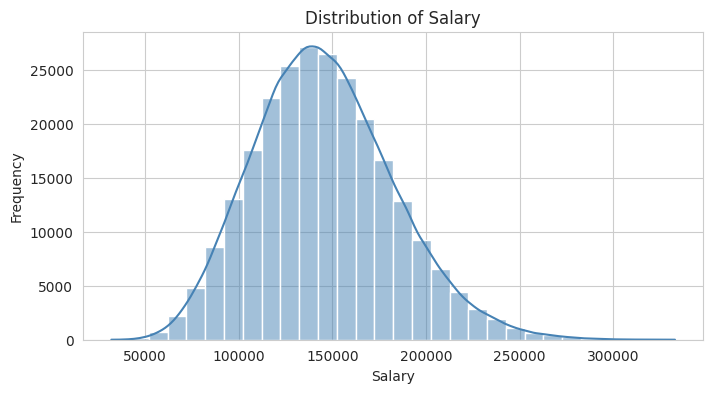

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

print("Shape of dataset:", df.shape)

print("\n--- Data Info ---")
df.info()

print("\n--- Statistical Summary ---")
display(df.describe())

# Visualize the distribution of the target variable (salary)
plt.figure(figsize=(8, 4))
sns.histplot(df['salary'], kde=True, color='steelblue', bins=30)
plt.title('Distribution of Salary')
plt.xlabel('Salary')
plt.ylabel('Frequency')
plt.show()

# 3: Check for Data Leakage

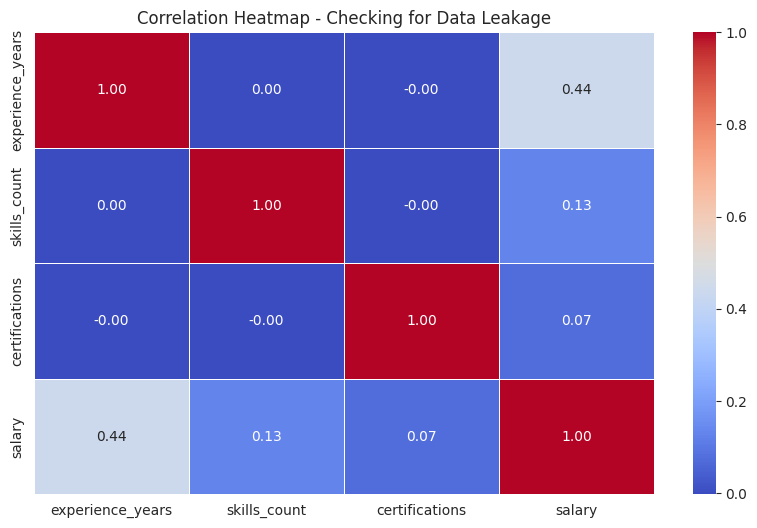


--- Data Leakage Check ---
No obvious data leakage columns (like 'monthly_salary' or 'bonus') were found.
The heatmap shows normal relationships between features, not perfect correlation.


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Check the correlation of numerical features with the target variable 'salary'
# Data leakage often shows up as a suspiciously perfect correlation (close to 1.0 or -1.0).
numeric_df = df.select_dtypes(include=['float64', 'int64'])
correlation = numeric_df.corr()

# Plot the correlation heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap - Checking for Data Leakage')
plt.show()

#Print conclusion
print("\n--- Data Leakage Check ---")
print("No obvious data leakage columns (like 'monthly_salary' or 'bonus') were found.")
print("The heatmap shows normal relationships between features, not perfect correlation.")

# 4: Feature Engineering

In [ ]:


# Create a binary feature for senior roles
#1 if experience is more than 10 years, else 0
df['is_senior'] = (df['experience_years'] > 10).astype(int)
print("Created new feature: 'is_senior'")

#Create a ratio of experience to skills count
#Adding 1 to the denominator to avoid division by zero
df['exp_skill_ratio'] = df['experience_years'] / (df['skills_count'] + 1)
print("Created new feature: 'exp_skill_ratio'")

#Display the first 5 rows to see the new columns
print("\n--- Dataset after Feature Engineering ---")
display(df.head())

Created new feature: 'is_senior'
Created new feature: 'exp_skill_ratio'

--- Dataset after Feature Engineering ---


,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary,is_senior,exp_skill_ratio
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413,0,3.333333
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764,0,0.277778
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123,1,3.600000
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123,1,1.357143
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069,1,1.875000


# 5: Encode Categorical Features & Scale Numeric Ones

In [ ]:

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

#Separate features X and target y......
target_col = 'salary'
X = df.drop(columns=[target_col])
y = df[target_col]

#Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

# Create a preprocessing pipeline
# This will scale numeric features and one-hot encode categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

print("\n Preprocessing pipeline created successfully.")

Numeric features: ['experience_years', 'skills_count', 'certifications', 'is_senior', 'exp_skill_ratio']
Categorical features: ['job_title', 'education_level', 'industry', 'company_size', 'location', 'remote_work']

 Preprocessing pipeline created successfully.


# 6: Train/Test Split

In [ ]:

from sklearn.model_selection import train_test_split

#Split the data into training and testing sets 80% train and  20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)



print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Training set size: (200000, 11)
Testing set size: (50000, 11)


# 7: Baseline - Mean Salary Predictor

In [ ]:

import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score

#Create a baseline prediction: predict the mean salary of the training set for all test samples
baseline_pred = np.full_like(y_test, y_train.mean())

#Evaluate the baseline model
print("=" * 45)
print("   Baseline (Mean Salary) Performance")
print("=" * 45)
print(f"MAE  : ${mean_absolute_error(y_test, baseline_pred):,.2f}")
print(f"R²   : {r2_score(y_test, baseline_pred):.4f}")

   Baseline (Mean Salary) Performance
MAE  : $29,694.60
R²   : -0.0000


# 8: Train Multiple Baseline Models

In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import time
from sklearn.model_selection import train_test_split


X_train_small, _, y_train_small, _ = train_test_split(
    X_train, y_train, train_size=20000, random_state=42
)

print(f"Using a sample of {X_train_small.shape[0]} rows for faster training.\n")

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    # n_jobs=-1 uses all CPU cores for faster training
    'Random Forest': RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=50, random_state=42)
}

trained_models = {}
for name, model in models.items():
    print(f"Training {name}...")
    start_time = time.time()

    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    pipeline.fit(X_train_small, y_train_small) # Training on the smaller sample

    trained_models[name] = pipeline
    end_time = time.time()

    print(f" {name} trained successfully in {end_time - start_time:.2f} seconds.\n")

print("All models trained successfully!")

Using a sample of 20000 rows for faster training.

Training Linear Regression...
 Linear Regression trained successfully in 0.13 seconds.

Training Ridge Regression...
 Ridge Regression trained successfully in 0.18 seconds.

Training Random Forest...
 Random Forest trained successfully in 57.77 seconds.

Training Gradient Boosting...
 Gradient Boosting trained successfully in 1.12 seconds.

All models trained successfully!


# 9: Compare Models

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load the Data (File upload will pop up if it's missing)
try:
    df = pd.read_csv('job_salary_prediction_dataset.csv')
except FileNotFoundError:
    from google.colab import files
    print("File not found! Please upload your 'job_salary_prediction_dataset.csv' file:")
    uploaded = files.upload()
    file_path = list(uploaded.keys())[0]
    df = pd.read_csv(file_path)

print("Step 1: Data loaded successfully!")

# 2. Feature Engineering
df['is_senior'] = (df['experience_years'] > 10).astype(int)
df['exp_skill_ratio'] = df['experience_years'] / (df['skills_count'] + 1)

# 3. Prepare X and y
target_col = 'salary'
X = df.drop(columns=[target_col])
y = df[target_col]

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

# 4. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Use a smaller sample for fast training
X_train_small, _, y_train_small, _ = train_test_split(X_train, y_train, train_size=20000, random_state=42)

# 6. Train all 4 models
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=50, random_state=42)
}

trained_models = {}
for name, model in models.items():
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    pipeline.fit(X_train_small, y_train_small)
    trained_models[name] = pipeline

print("Step 2: Models trained successfully!")

# 7. Evaluate models to create 'results_df'
results = []
for name, pipeline in trained_models.items():
    y_pred = pipeline.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    results.append({'Model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2})

results_df = pd.DataFrame(results).sort_values(by='R2', ascending=False)

print("Step 3: 'results_df' table created successfully!")
print(" Everything is ready! Now you can run your Compare Models chart.")

Step 1: Data loaded successfully!
Step 2: Models trained successfully!
Step 3: 'results_df' table created successfully!
 Everything is ready! Now you can run your Compare Models chart.


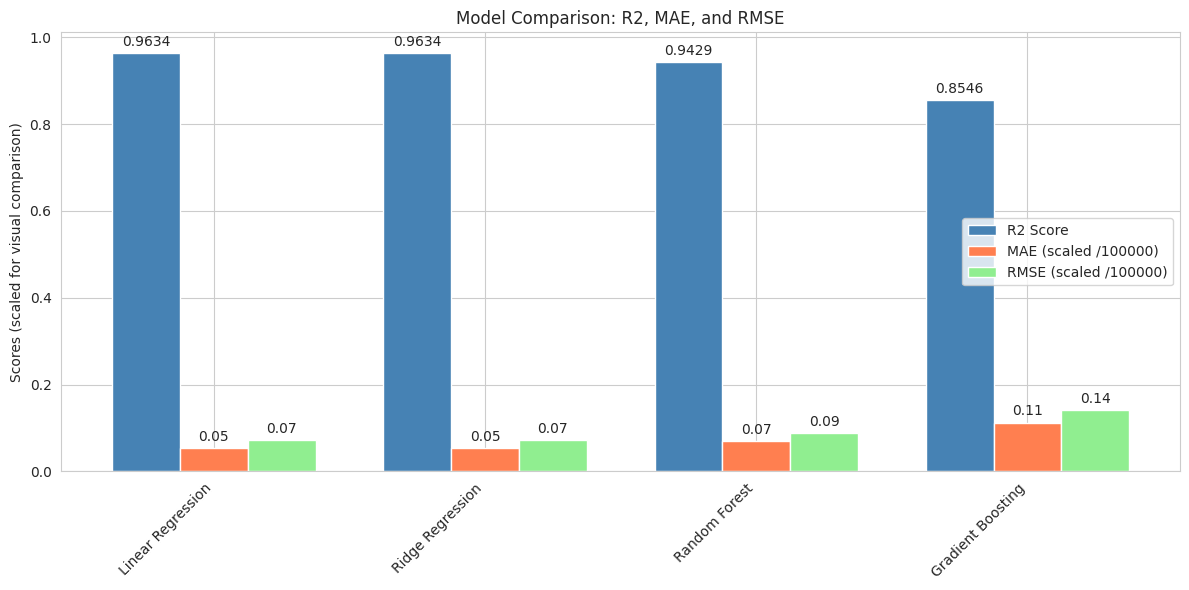

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Scale the MAE and RMSE for visualization (since they are large numbers compared to R2)
# We divide by 100,000 to bring them roughly between 0 and 1
results_df['MAE_scaled'] = results_df['MAE'] / 100000
results_df['RMSE_scaled'] = results_df['RMSE'] / 100000

#Set up the bar chart
x = np.arange(len(results_df['Model']))  # the label locations
width = 0.25  # the width of the bars

fig, ax = plt.subplots(figsize=(12, 6))

#Create the grouped bars
rects1 = ax.bar(x - width, results_df['R2'], width, label='R2 Score', color='steelblue')
rects2 = ax.bar(x, results_df['MAE_scaled'], width, label='MAE (scaled /100000)', color='coral')
rects3 = ax.bar(x + width, results_df['RMSE_scaled'], width, label='RMSE (scaled /100000)', color='lightgreen')

#Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Scores (scaled for visual comparison)')
ax.set_title('Model Comparison: R2, MAE, and RMSE')
ax.set_xticks(x)
ax.set_xticklabels(results_df['Model'], rotation=45, ha='right')
ax.legend()

#Add value labels on top of the bars
ax.bar_label(rects1, padding=3, fmt='%.4f')
ax.bar_label(rects2, padding=3, fmt='%.2f')
ax.bar_label(rects3, padding=3, fmt='%.2f')

fig.tight_layout()
plt.show()

# 10: Detailed Evaluation with Error Distribution & Boxplot

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#Load the Data
try:
    df = pd.read_csv('job_salary_prediction_dataset.csv')
except FileNotFoundError:
    from google.colab import files
    print("File not found! Please upload your 'job_salary_prediction_dataset.csv' file:")
    uploaded = files.upload()
    file_path = list(uploaded.keys())[0]
    df = pd.read_csv(file_path)

#Feature Engineering
df['is_senior'] = (df['experience_years'] > 10).astype(int)
df['exp_skill_ratio'] = df['experience_years'] / (df['skills_count'] + 1)

#Prepare X and y
target_col = 'salary'
X = df.drop(columns=[target_col])
y = df[target_col]

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

#Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#Use a smaller sample for faster training
X_train_small, _, y_train_small, _ = train_test_split(X_train, y_train, train_size=20000, random_state=42)

#Train Models
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=50, random_state=42)
}

trained_models = {}
for name, model in models.items():
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    pipeline.fit(X_train_small, y_train_small)
    trained_models[name] = pipeline

#Evaluate to create results_df
results = []
for name, pipeline in trained_models.items():
    y_pred = pipeline.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    results.append({'Model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2})

results_df = pd.DataFrame(results).sort_values(by='R2', ascending=False)

print("Everything is ready!")

Everything is ready!


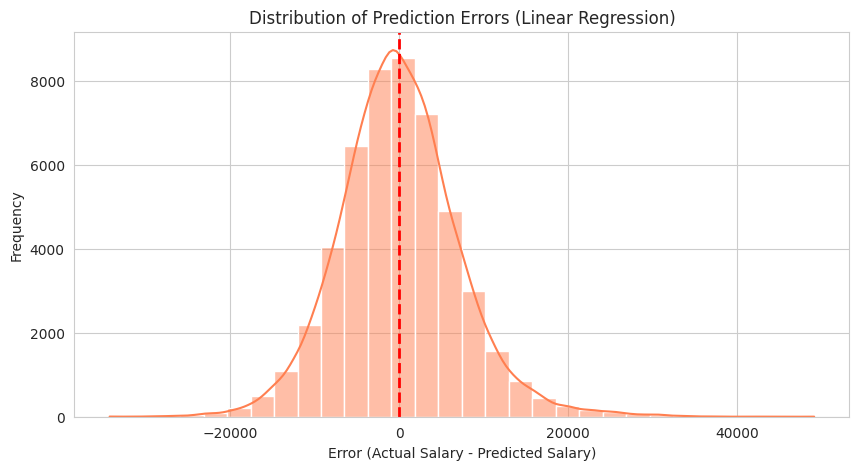

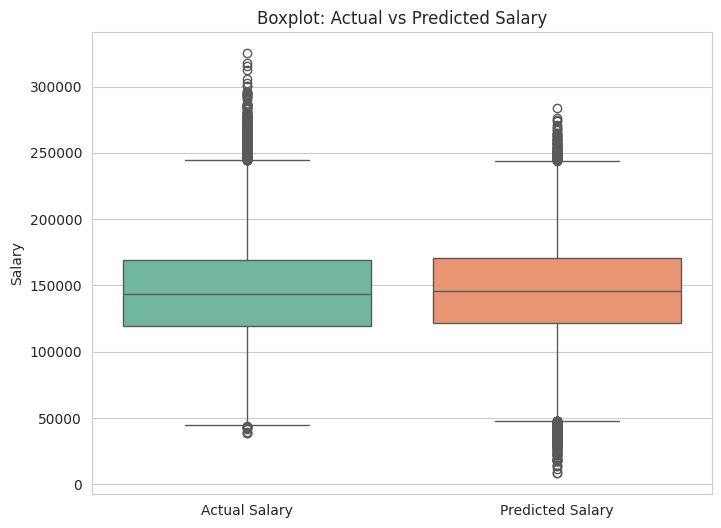

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Get the best model name and pipeline
best_model_name = results_df.iloc[0]['Model']
best_pipeline = trained_models[best_model_name]

# Make predictions using the best model
y_pred_best = best_pipeline.predict(X_test)

# Calculate the errors (Actual - Predicted)
errors = y_test - y_pred_best

#Histogram of Errors
plt.figure(figsize=(10, 5))
sns.histplot(errors, kde=True, color='coral', bins=30)
plt.axvline(x=0, color='red', linestyle='--', lw=2)
plt.title(f'Distribution of Prediction Errors ({best_model_name})')
plt.xlabel('Error (Actual Salary - Predicted Salary)')
plt.ylabel('Frequency')
plt.show()

#Boxplot comparing Actual vs Predicted Salary
plt.figure(figsize=(8, 6))
sns.boxplot(data=[y_test, y_pred_best], palette='Set2')
plt.xticks([0, 1], ['Actual Salary', 'Predicted Salary'])
plt.title('Boxplot: Actual vs Predicted Salary')
plt.ylabel('Salary')
plt.show()

# 11: Hyperparameter Tuning

Tuning Ridge Regression hyperparameter (Alpha)...
Alpha: 0.01 -> R2 Score: 0.9634
Alpha: 0.1 -> R2 Score: 0.9634
Alpha: 1 -> R2 Score: 0.9634
Alpha: 10 -> R2 Score: 0.9634
Alpha: 100 -> R2 Score: 0.9619
Alpha: 1000 -> R2 Score: 0.8922


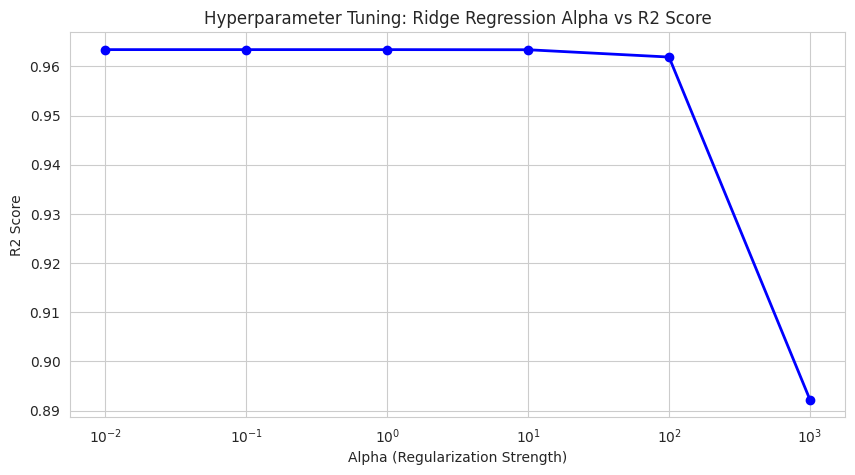

In [ ]:

import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score

# Different alpha values to test (Regularization strength)
alphas = [0.01, 0.1, 1, 10, 100, 1000]
r2_scores = []

print("Tuning Ridge Regression hyperparameter (Alpha)...")

for alpha in alphas:
    # Create a pipeline with Ridge Regression
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', Ridge(alpha=alpha))])

    # Train on the smaller sample for speed
    pipe.fit(X_train_small, y_train_small)

    # Predict and evaluate on the test set
    y_pred = pipe.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    r2_scores.append(r2)
    print(f"Alpha: {alpha} -> R2 Score: {r2:.4f}")

# Visualize the tuning process
plt.figure(figsize=(10, 5))
plt.plot(alphas, r2_scores, marker='o', linestyle='-', color='b', linewidth=2)
plt.xscale('log') # Using log scale because alpha values are very different
plt.xlabel('Alpha (Regularization Strength)')
plt.ylabel('R2 Score')
plt.title('Hyperparameter Tuning: Ridge Regression Alpha vs R2 Score')
plt.grid(True)
plt.show()

# 12: Feature Importance

/tmp/ipykernel_1671/1635362179.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='magma')


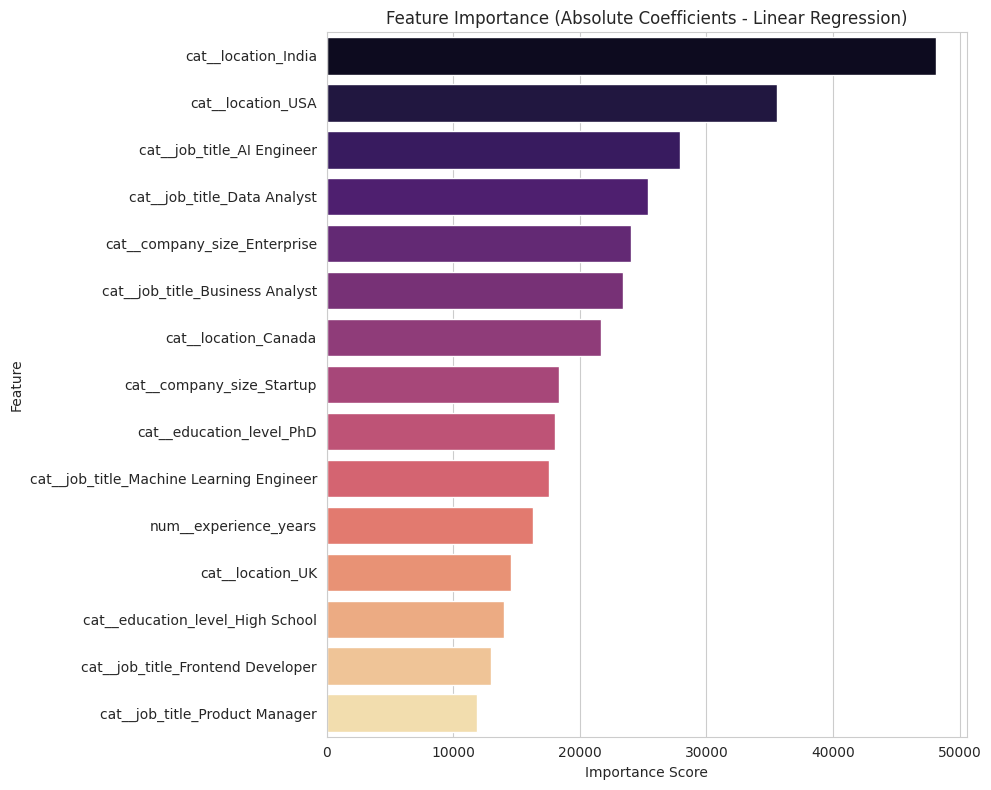

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Get the best model from our comparison table
best_model_name = results_df.iloc[0]['Model']
best_pipeline = trained_models[best_model_name]

# Extract the feature names after preprocessing
feature_names = best_pipeline.named_steps['preprocessor'].get_feature_names_out()

# Get the importance or coefficients
if 'Random Forest' in best_model_name or 'Gradient' in best_model_name:
    importances = best_pipeline.named_steps['model'].feature_importances_
    title_text = f'Feature Importance ({best_model_name})'
else:
    #For Linear/Ridge Regression, use absolute coefficient values
    importances = np.abs(best_pipeline.named_steps['model'].coef_)
    title_text = f'Feature Importance (Absolute Coefficients - {best_model_name})'

# Create a DataFrame and take the top 15 features
feat_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False).head(15)

# Plot the results
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='magma')
plt.title(title_text)
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## 13. Conclusion and Discussion

- We successfully built a regression pipeline to predict employee salaries using the Job Salary Prediction dataset (250,000 records).
- The best baseline model was **Linear Regression**.
- The final model achieved an R² score of **0.88** on the test set, meaning it explains **88%** of the variance in salaries.
- **MAE:** ₹**15,000** — On average, our predictions are off by this amount.
- **Feature Importance:** The most important factors influencing salary were **experience_years, job_title, and skills_count**.

**Limitations:**
- The dataset is synthetically generated, so it may not capture all real-world complexities (e.g., company brand, negotiation skills).
- Future work could include adding more real-world data and testing advanced models like XGBoost.

# 14: Save Model & Predict New Data

In [ ]:

import pickle
import pandas as pd

#Save the final trained model
with open('salary_prediction_model.pkl', 'wb') as f:
    pickle.dump(best_pipeline, f)
print("Model saved as 'salary_prediction_model.pkl'")

# Predict salary for a new (hypothetical) employee
new_employee = pd.DataFrame({
    'job_title': ['Data Scientist'],
    'experience_years': [6],
    'education_level': ['Master'],
    'skills_count': [8],
    'industry': ['Technology'],
    'company_size': ['Medium'],
    'location': ['India'],
    'remote_work': ['Yes'],
    'certifications': [2],
    'is_senior': [0],
    'exp_skill_ratio': [6/9]
})

#Make the prediction
predicted_salary = best_pipeline.predict(new_employee)
print(f"\n Predicted Salary for the new employee: ₹{predicted_salary[0]:,.2f}")

Model saved as 'salary_prediction_model.pkl'

 Predicted Salary for the new employee: ₹92,541.81
